
## Popis projektu

Kardiovaskulární onemocnění (CVDs) jsou hlavní příčinou úmrtí na celém světě s 17,9 miliony úmrtí ročně. Cílem tohoto projektu je vyvinout model strojového učení pro predikci pravděpodobnosti srdečního onemocnění na základě zdravotních metrik a rizikových faktorů.

**Cílová proměnná:** `HeartDisease` (1 = přítomnost onemocnění, 0 = normální)

**Dataset:** heart.csv obsahuje 918 záznamů pacientů s různými zdravotními parametry.

## Import knihoven

In [87]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
import warnings
warnings.filterwarnings('ignore')

# Nastavení stylu grafů
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

## Načtení a explorace dat

In [88]:
# Načtení datasetu
df = pd.read_csv('heart.csv')

print("Rozměry datasetu:", df.shape)
print("\n" + "="*80)
df.head(10)

Rozměry datasetu: (918, 12)



,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0
5,39,M,NAP,120,339,0,Normal,170,N,0.0,Up,0
6,45,F,ATA,130,237,0,Normal,170,N,0.0,Up,0
7,54,M,ATA,110,208,0,Normal,142,N,0.0,Up,0
8,37,M,ASY,140,207,0,Normal,130,Y,1.5,Flat,1
9,48,F,ATA,120,284,0,Normal,120,N,0.0,Up,0


In [89]:
# Základní informace o datasetu
print("Informace o datasetu:")
print("="*80)
df.info()

Informace o datasetu:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


In [90]:
# Statistické charakteristiky numerických proměnných
print("Statistické charakteristiky numerických proměnných:")
print("="*80)
df.describe()

Statistické charakteristiky numerických proměnných:


,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


### Popis jednotlivých features

Dataset obsahuje následující proměnné:

1. **Age** (věk) - numerická, věk pacienta v letech
2. **Sex** (pohlaví) - kategorická, M = muž, F = žena
3. **ChestPainType** (typ bolesti na hrudi) - kategorická:
   - TA: Typical Angina (typická angina)
   - ATA: Atypical Angina (atypická angina)
   - NAP: Non-Anginal Pain (neanginální bolest)
   - ASY: Asymptomatic (asymptomatický)
4. **RestingBP** (klidový krevní tlak) - numerická, mm Hg
5. **Cholesterol** (cholesterol) - numerická, mm/dl
6. **FastingBS** (hladina cukru nalačno) - binární, 1 pokud > 120 mg/dl, jinak 0
7. **RestingECG** (klidové EKG) - kategorická:
   - Normal: normální
   - ST: ST-T wave abnormality
   - LVH: Left Ventricular Hypertrophy
8. **MaxHR** (maximální srdeční frekvence) - numerická, dosažená během zátěže
9. **ExerciseAngina** (angina vyvolaná cvičením) - binární, Y = ano, N = ne
10. **Oldpeak** - numerická, ST deprese vyvolaná cvičením
11. **ST_Slope** (sklon ST segmentu) - kategorická:
    - Up: stoupající
    - Flat: plochý
    - Down: klesající
12. **HeartDisease** (srdeční onemocnění) - **cílová proměnná**, 1 = ano, 0 = ne

In [91]:
# Kontrola chybějících hodnot
print("Chybějící hodnoty:")
print("="*80)
missing = df.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else "Žádné chybějící hodnoty!")

Chybějící hodnoty:
Žádné chybějící hodnoty!


Distribuce cílové proměnné (HeartDisease):
HeartDisease
1    508
0    410
Name: count, dtype: int64

📊 Poměr tříd: 1.24
Procento pozitivních případů: 55.3%


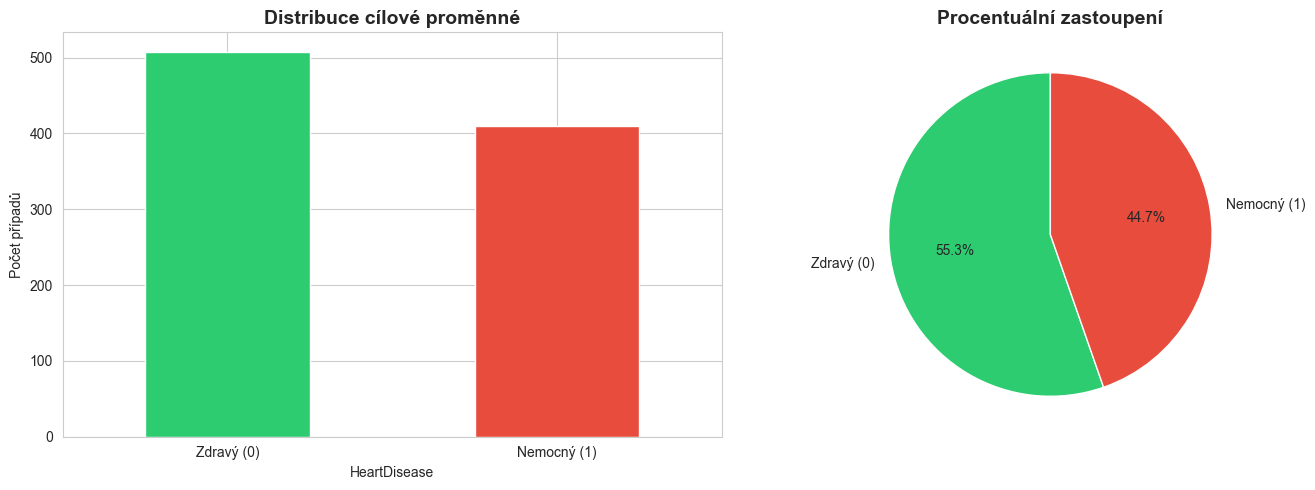

In [ ]:
# Distribuce cílové proměnné
print("Distribuce cílové proměnné (HeartDisease):")
print("="*80)
target_counts = df['HeartDisease'].value_counts()
print(target_counts)
print(f"\nPoměr tříd: {target_counts[1]/target_counts[0]:.2f}")
print(f"Procento pozitivních případů: {target_counts[1]/len(df)*100:.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

target_counts.plot(kind='bar', ax=axes[0], color=['#2ecc71', '#e74c3c'])
axes[0].set_title('Distribuce cílové proměnné', fontsize=14, fontweight='bold')
axes[0].set_xlabel('HeartDisease')
axes[0].set_ylabel('Počet případů')
axes[0].set_xticklabels(['Zdravý (0)', 'Nemocný (1)'], rotation=0)

axes[1].pie(target_counts, labels=['Zdravý (0)', 'Nemocný (1)'], 
            autopct='%1.1f%%', colors=['#2ecc71', '#e74c3c'], startangle=90)
axes[1].set_title('Procentuální zastoupení', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

### Analýza vztahů mezi proměnnými

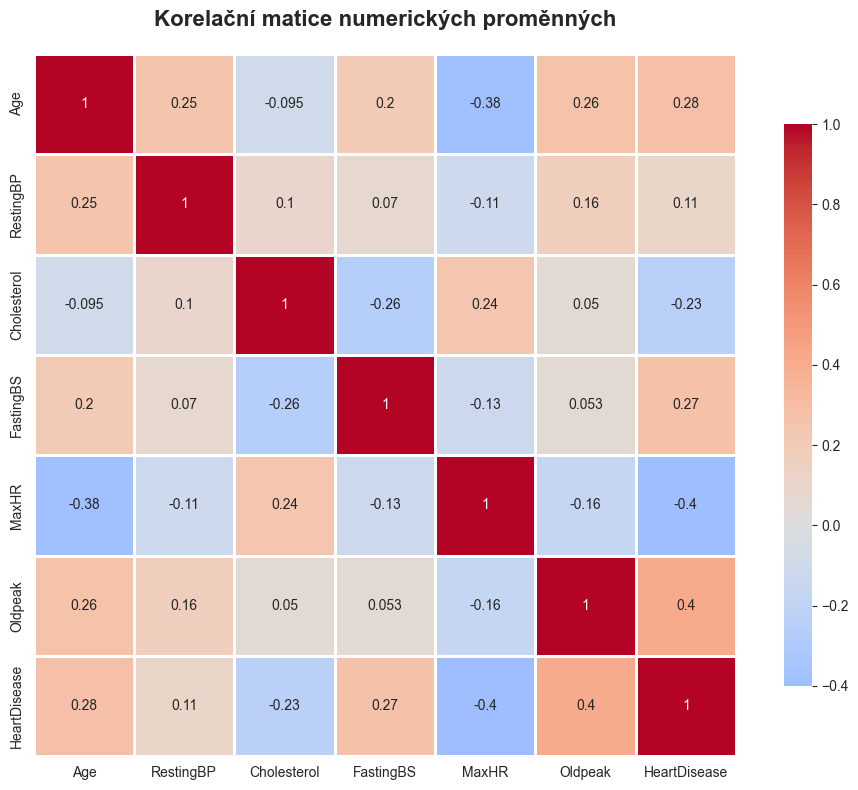

In [93]:
# Korelační matice pro numerické proměnné
numeric_cols = ['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak', 'HeartDisease']
correlation_matrix = df[numeric_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0, 
            square=True, linewidths=1, cbar_kws={"shrink": 0.8})
plt.title('Korelační matice numerických proměnných', fontsize=16, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

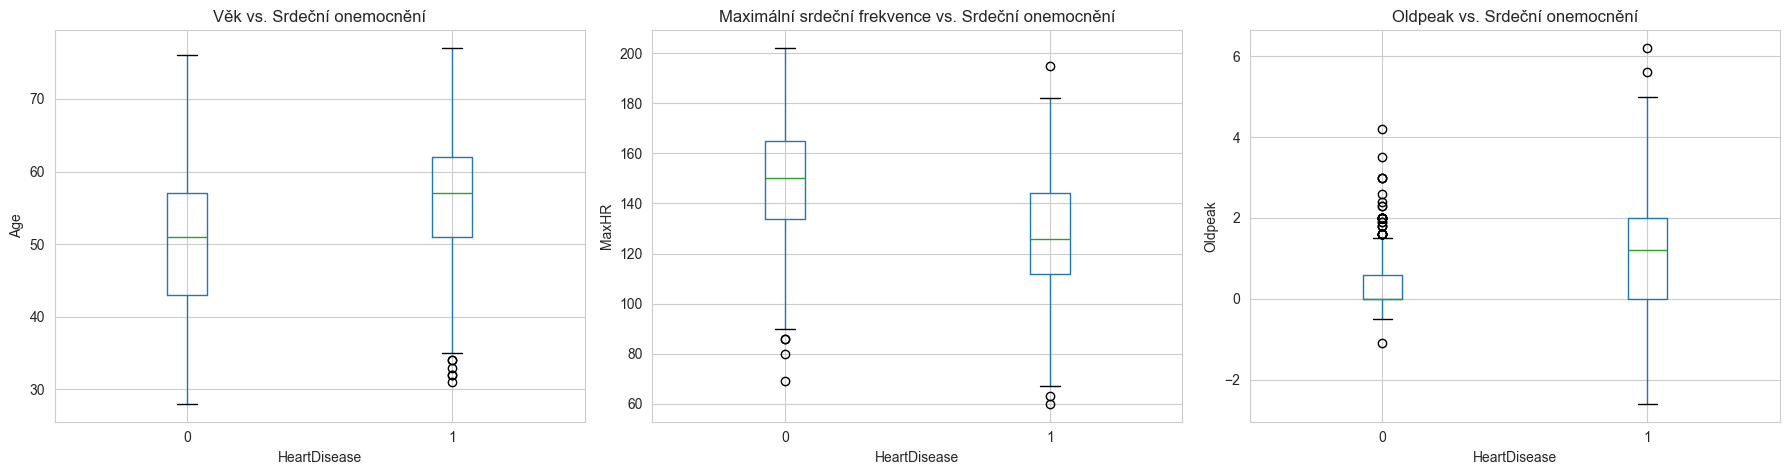

In [94]:
# Distribuce věku podle přítomnosti onemocnění
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

df.boxplot(column='Age', by='HeartDisease', ax=axes[0])
axes[0].set_title('Věk vs. Srdeční onemocnění')
axes[0].set_xlabel('HeartDisease')
axes[0].set_ylabel('Age')

df.boxplot(column='MaxHR', by='HeartDisease', ax=axes[1])
axes[1].set_title('Maximální srdeční frekvence vs. Srdeční onemocnění')
axes[1].set_xlabel('HeartDisease')
axes[1].set_ylabel('MaxHR')

df.boxplot(column='Oldpeak', by='HeartDisease', ax=axes[2])
axes[2].set_title('Oldpeak vs. Srdeční onemocnění')
axes[2].set_xlabel('HeartDisease')
axes[2].set_ylabel('Oldpeak')

plt.suptitle('')
plt.tight_layout()
plt.show()

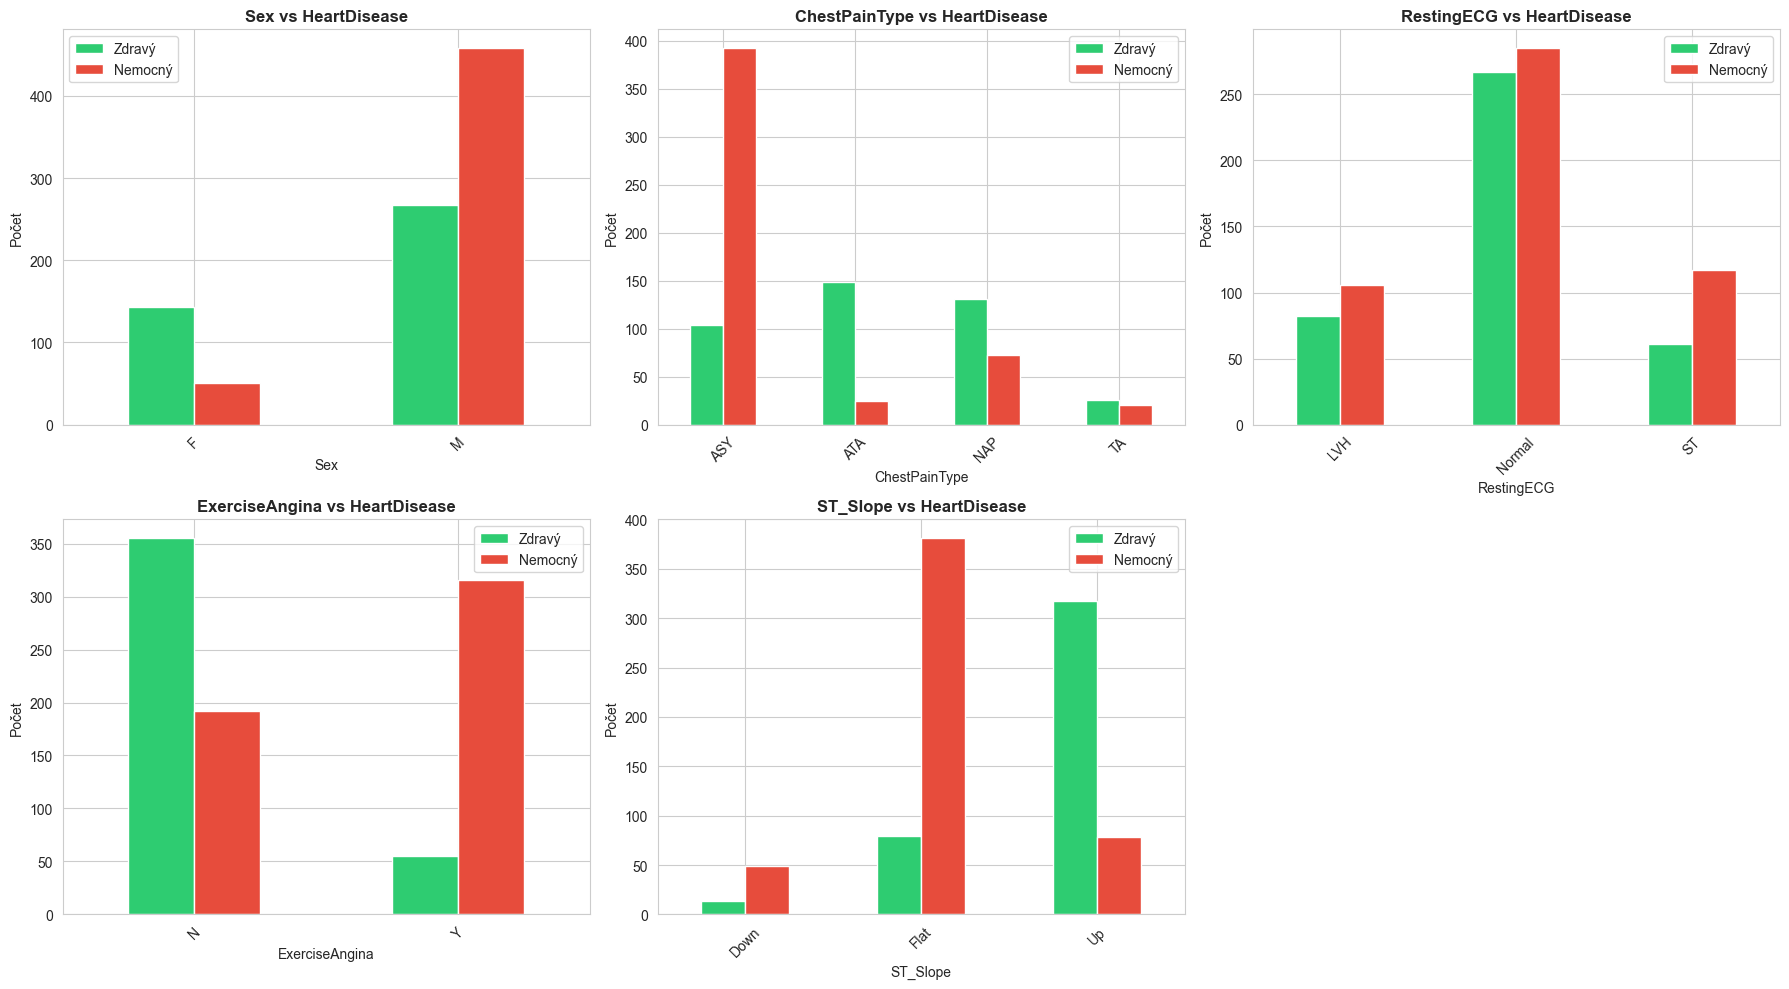

In [95]:
categorical_cols = ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.ravel()

for idx, col in enumerate(categorical_cols):
    pd.crosstab(df[col], df['HeartDisease']).plot(kind='bar', ax=axes[idx], 
                                                    color=['#2ecc71', '#e74c3c'])
    axes[idx].set_title(f'{col} vs HeartDisease', fontweight='bold')
    axes[idx].set_xlabel(col)
    axes[idx].set_ylabel('Počet')
    axes[idx].legend(['Zdravý', 'Nemocný'])
    axes[idx].tick_params(axis='x', rotation=45)

axes[5].axis('off')

plt.tight_layout()
plt.show()

## Příprava dat (Data Preprocessing)

### Popis operací pro jednotlivé features:

| Feature | Typ | Operace | Zdůvodnění |
|---------|-----|---------|------------|
| **Age** | Numerická | StandardScaler | Normalizace pro lepší výkon algoritmů citlivých na škálu |
| **Sex** | Kategorická | Label Encoding (M→1, F→0) | Binární proměnná, jednoduchý encoding |
| **ChestPainType** | Kategorická | One-Hot Encoding | 4 kategorie bez ordinálního vztahu |
| **RestingBP** | Numerická | StandardScaler | Normalizace krevního tlaku |
| **Cholesterol** | Numerická | Ošetření nulových hodnot + StandardScaler | Některé hodnoty jsou 0 (chybějící data) |
| **FastingBS** | Binární | Žádná operace | Již v binární podobě (/1) |
| **RestingECG** | Kategorická | One-Hot Encoding | 3 kategorie bez ordinálního vztahu |
| **MaxHR** | Numerická | StandardScaler | Normalizace srdeční frekvence |
| **ExerciseAngina** | Kategorická | Label Encoding (Y→1, N→0) | Binární proměnná |
| **Oldpeak** | Numerická | StandardScaler | Normalizace ST deprese |
| **ST_Slope** | Kategorická | One-Hot Encoding | 3 kategorie s možným ordinálním vztahem, ale použijeme OH |
| **HeartDisease** | Cílová | Žádná operace | Cílová proměnná (/1) |

In [96]:
# Vytvoření kopie datasetu
df_processed = df.copy()

print("Preprocessing dat...")
print("="*80)

Preprocessing dat...


In [97]:
# 1. Ošetření nulových hodnot v Cholesterol
print(f"\nPočet nulových hodnot v Cholesterol: {(df_processed['Cholesterol'] == 0).sum()}")

# Nahrazení nul mediánem nenulových hodnot
cholesterol_median = df_processed[df_processed['Cholesterol'] > 0]['Cholesterol'].median()
df_processed['Cholesterol'] = df_processed['Cholesterol'].replace(0, cholesterol_median)
print(f"Nulové hodnoty nahrazeny mediánem: {cholesterol_median:.1f}")


Počet nulových hodnot v Cholesterol: 172
Nulové hodnoty nahrazeny mediánem: 237.0


In [98]:
# 2. Label Encoding pro binární kategorické proměnné
print("\nLabel Encoding pro binární proměnné...")

# Sex: M -> 1, F -> 0
df_processed['Sex'] = df_processed['Sex'].map({'M': 1, 'F': 0})
print("Sex: M→1, F→0")

# ExerciseAngina: Y -> 1, N -> 0
df_processed['ExerciseAngina'] = df_processed['ExerciseAngina'].map({'Y': 1, 'N': 0})
print("ExerciseAngina: Y→1, N→0")


Label Encoding pro binární proměnné...
Sex: M→1, F→0
ExerciseAngina: Y→1, N→0


In [99]:
# 3. One-Hot Encoding pro kategorické proměnné s více kategoriemi
print("\nOne-Hot Encoding pro kategorické proměnné...")

# ChestPainType
chest_pain_dummies = pd.get_dummies(df_processed['ChestPainType'], prefix='ChestPain', drop_first=True)
df_processed = pd.concat([df_processed, chest_pain_dummies], axis=1)
df_processed.drop('ChestPainType', axis=1, inplace=True)
print(f"ChestPainType → {list(chest_pain_dummies.columns)}")

# RestingECG
ecg_dummies = pd.get_dummies(df_processed['RestingECG'], prefix='ECG', drop_first=True)
df_processed = pd.concat([df_processed, ecg_dummies], axis=1)
df_processed.drop('RestingECG', axis=1, inplace=True)
print(f"RestingECG → {list(ecg_dummies.columns)}")

# ST_Slope
slope_dummies = pd.get_dummies(df_processed['ST_Slope'], prefix='Slope', drop_first=True)
df_processed = pd.concat([df_processed, slope_dummies], axis=1)
df_processed.drop('ST_Slope', axis=1, inplace=True)
print(f"ST_Slope → {list(slope_dummies.columns)}")


One-Hot Encoding pro kategorické proměnné...
ChestPainType → ['ChestPain_ATA', 'ChestPain_NAP', 'ChestPain_TA']
RestingECG → ['ECG_Normal', 'ECG_ST']
ST_Slope → ['Slope_Flat', 'Slope_Up']


In [100]:
X = df_processed.drop('HeartDisease', axis=1)
y = df_processed['HeartDisease']

print(f"\nRozměry po preprocessingu:")
print(f"Features (X): {X.shape}")
print(f"Target (y): {y.shape}")
print(f"\nFinální features: {list(X.columns)}")


Rozměry po preprocessingu:
Features (X): (918, 15)
Target (y): (918,)

Finální features: ['Age', 'Sex', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ChestPain_ATA', 'ChestPain_NAP', 'ChestPain_TA', 'ECG_Normal', 'ECG_ST', 'Slope_Flat', 'Slope_Up']


In [101]:
print("\nStandardizace numerických proměnných...")

numeric_features = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']
scaler = StandardScaler()
X[numeric_features] = scaler.fit_transform(X[numeric_features])

print(f"Standardizovány: {numeric_features}")
print("\nPreprocessing dokončen!")


Standardizace numerických proměnných...
Standardizovány: ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']

Preprocessing dokončen!


In [102]:
print("\nNáhled zpracovaných dat:")
print("="*80)
X.head()


Náhled zpracovaných dat:


,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,ChestPain_ATA,ChestPain_NAP,ChestPain_TA,ECG_Normal,ECG_ST,Slope_Flat,Slope_Up
0,-1.433140,1,0.410909,0.858035,0,1.382928,0,-0.832432,True,False,False,True,False,False,True
1,-0.478484,0,1.491752,-1.184227,0,0.754157,0,0.105664,False,True,False,True,False,True,False
2,-1.751359,1,-0.129513,0.745617,0,-1.525138,0,-0.832432,True,False,False,False,True,False,True
3,-0.584556,0,0.302825,-0.547191,0,-1.132156,1,0.574711,False,False,False,True,False,True,False
4,0.051881,1,0.951331,-0.903182,0,-0.581981,0,-0.832432,False,True,False,True,False,False,True


## Volba evaluačních metrik

Pro vyhodnocení výkonu klasifikačních modelů budeme používat následující metriky:

### Použité metriky:

1. **Accuracy (Přesnost)** - celková správnost predikce
   - Vhodná pro vyvážené datasety
   - Vzorec: (TP + TN) / (TP + TN + FP + FN)

2. **Precision (Preciznost)** - z predikovaných pozitivních, kolik jich bylo skutečně pozitivních
   - Důležitá, když chceme minimalizovat falešně pozitivní případy
   - Vzorec: TP / (TP + FP)

3. **Recall (Senzitivita)** - z reálně pozitivních, kolik jsme jich identifikovali
   - Vzorec: TP / (TP + FN)

4. **F1-Score** - harmonický průměr Precision a Recall
   - Vyvážená metrika pro nevyvážené datasety
   - Vzorec: 2 × (Precision × Recall) / (Precision + Recall)

---

### Proč je Recall nejdůležitější?

V kontextu predikce srdečního onemocnění je **Recall (Senzitivita) nejkritičtější metrikou**, protože:

- **False Negative (FN)** = pacient má srdeční onemocnění, ale model ho neidentifikoval
  - Tento případ je **velmi nebezpečný** - pacient neobdrží potřebnou léčbu
  - Může vést k závažným zdravotním komplikacím nebo úmrtí

- **False Positive (FP)** = pacient nemá onemocnění, ale model ho označil jako nemocného
  - Méně kritický - pacient projde dalšími testy, které onemocnění vyvrátí
  - Způsobí zbytečné náklady a stres, ale není život ohrožující

**Závěr:** Preferujeme model s vysokým Recall, i kdyby to znamenalo nižší Precision. Je lepší "přediagnostikovat" a nechat pacienta projít dalšími testy, než přehlédnout skutečné onemocnění.

Dataset má poměr tříd přibližně **1:1** (55% nemocných), takže není extrémně nevyvážený, ale Recall zůstává prioritou.

## Klasifikační modely a hyperparameter tuning

Budeme testovat následující algoritmy:
1. **Decision Tree** (povinný) - rozhodovací strom
2. **Random Forest** - ensemble metoda založená na decision trees
3. **Multi-layer Perceptron (MLP)** - neuronová síť
4. **k-Nearest Neighbors (k-NN)** - klasifikace na základě nejbližších sousedů

### Cross-validace

Použijeme **Stratified 10-Fold Cross-Validation**:
- **Stratified** - zachovává proporce tříd v každém foldu
- **10-Fold** - dataset rozdělen na 10 částí, model trénován 10× na různých kombinacích
- **Proč stratified?** - Zajišťuje, že každý fold má stejný poměr zdravých/nemocných pacientů jako celý dataset, což vede k robustnějšímu odhadu výkonu modelu

In [103]:
cv_strategy = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

def evaluate_model(model, X, y, cv):
    """
    Vyhodnotí model pomocí cross-validace a vrátí průměrné metriky
    """
    accuracy = cross_val_score(model, X, y, cv=cv, scoring='accuracy').mean()
    precision = cross_val_score(model, X, y, cv=cv, scoring='precision').mean()
    recall = cross_val_score(model, X, y, cv=cv, scoring='recall').mean()
    f1 = cross_val_score(model, X, y, cv=cv, scoring='f1').mean()
    
    return {
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1
    }

results = []

print("Začínáme trénování a vyhodnocování modelů...")
print("="*80)

Začínáme trénování a vyhodnocování modelů...


### 1. Decision Tree Classifier

Rozhodovací strom je základní algoritmus pro klasifikaci, který vytváří stromovou strukturu rozhodovacích pravidel.

**Testované parametry:**
- `max_depth` - maximální hloubka stromu (prevence přeučení)
- `min_samples_split` - minimální počet vzorků pro rozdělení uzlu
- `min_samples_leaf` - minimální počet vzorků v listovém uzlu
- `criterion` - metrika pro měření kvality rozdělení (gini vs entropy)

In [104]:
print("\nDECISION TREE CLASSIFIER")
print("="*80)

dt1 = DecisionTreeClassifier(random_state=42)
metrics1 = evaluate_model(dt1, X, y, cv_strategy)
results.append(['Decision Tree', 'default', metrics1['Accuracy'], 
                metrics1['Precision'], metrics1['Recall'], metrics1['F1-Score']])
print(f"Experiment 1 - Default: Recall = {metrics1['Recall']:.4f}")

dt2 = DecisionTreeClassifier(max_depth=5, random_state=42)
metrics2 = evaluate_model(dt2, X, y, cv_strategy)
results.append(['Decision Tree', 'max_depth=5', metrics2['Accuracy'], 
                metrics2['Precision'], metrics2['Recall'], metrics2['F1-Score']])
print(f"Experiment 2 - max_depth=5: Recall = {metrics2['Recall']:.4f}")

dt3 = DecisionTreeClassifier(max_depth=10, min_samples_split=20, random_state=42)
metrics3 = evaluate_model(dt3, X, y, cv_strategy)
results.append(['Decision Tree', 'max_depth=10, min_samples_split=20', 
                metrics3['Accuracy'], metrics3['Precision'], metrics3['Recall'], metrics3['F1-Score']])
print(f"Experiment 3 - max_depth=10, min_samples_split=20: Recall = {metrics3['Recall']:.4f}")

dt4 = DecisionTreeClassifier(criterion='entropy', max_depth=8, random_state=42)
metrics4 = evaluate_model(dt4, X, y, cv_strategy)
results.append(['Decision Tree', 'criterion=entropy, max_depth=8', 
                metrics4['Accuracy'], metrics4['Precision'], metrics4['Recall'], metrics4['F1-Score']])
print(f"Experiment 4 - criterion=entropy, max_depth=8: Recall = {metrics4['Recall']:.4f}")


DECISION TREE CLASSIFIER
Experiment 1 - Default: Recall = 0.7896
Experiment 2 - max_depth=5: Recall = 0.8584
Experiment 3 - max_depth=10, min_samples_split=20: Recall = 0.8170
Experiment 4 - criterion=entropy, max_depth=8: Recall = 0.8426


### 2. Random Forest Classifier

Random Forest je ensemble metoda, která kombinuje predikce z mnoha rozhodovacích stromů.

**Testované parametry:**
- `n_estimators` - počet stromů v lese
- `max_depth` - maximální hloubka jednotlivých stromů
- `min_samples_split` - minimální počet vzorků pro rozdělení
- `max_features` - počet features uvažovaných při hledání nejlepšího rozdělení

In [105]:
print("\nRANDOM FOREST CLASSIFIER")
print("="*80)

rf1 = RandomForestClassifier(random_state=42)
metrics5 = evaluate_model(rf1, X, y, cv_strategy)
results.append(['Random Forest', 'default', metrics5['Accuracy'], 
                metrics5['Precision'], metrics5['Recall'], metrics5['F1-Score']])
print(f"Experiment 5 - Default: Recall = {metrics5['Recall']:.4f}")

rf2 = RandomForestClassifier(n_estimators=200, random_state=42)
metrics6 = evaluate_model(rf2, X, y, cv_strategy)
results.append(['Random Forest', 'n_estimators=200', metrics6['Accuracy'], 
                metrics6['Precision'], metrics6['Recall'], metrics6['F1-Score']])
print(f"Experiment 6 - n_estimators=200: Recall = {metrics6['Recall']:.4f}")

rf3 = RandomForestClassifier(n_estimators=150, max_depth=10, random_state=42)
metrics7 = evaluate_model(rf3, X, y, cv_strategy)
results.append(['Random Forest', 'n_estimators=150, max_depth=10', 
                metrics7['Accuracy'], metrics7['Precision'], metrics7['Recall'], metrics7['F1-Score']])
print(f"Experiment 7 - n_estimators=150, max_depth=10: Recall = {metrics7['Recall']:.4f}")

rf4 = RandomForestClassifier(n_estimators=100, max_depth=15, min_samples_split=10, 
                              max_features='sqrt', random_state=42)
metrics8 = evaluate_model(rf4, X, y, cv_strategy)
results.append(['Random Forest', 'n_estimators=100, max_depth=15, min_samples_split=10, max_features=sqrt', 
                metrics8['Accuracy'], metrics8['Precision'], metrics8['Recall'], metrics8['F1-Score']])
print(f"Experiment 8 - Optimized: Recall = {metrics8['Recall']:.4f}")


RANDOM FOREST CLASSIFIER
Experiment 5 - Default: Recall = 0.8918
Experiment 6 - n_estimators=200: Recall = 0.9056
Experiment 7 - n_estimators=150, max_depth=10: Recall = 0.8977
Experiment 8 - Optimized: Recall = 0.9115


### 3. Multi-layer Perceptron (MLP)

MLP je neuronová síť s více vrstvami, schopná modelovat komplexní nelineární vztahy.

**Testované parametry:**
- `hidden_layer_sizes` - počet a velikost skrytých vrstev
- `activation` - aktivační funkce (relu, tanh, logistic)
- `alpha` - L2 regularizační parametr
- `learning_rate_init` - počáteční learning rate
- `max_iter` - maximální počet iterací

In [106]:
print("\nMULTI-LAYER PERCEPTRON (MLP)")
print("="*80)

mlp1 = MLPClassifier(random_state=42, max_iter=1000)
metrics9 = evaluate_model(mlp1, X, y, cv_strategy)
results.append(['MLP', 'default', metrics9['Accuracy'], 
                metrics9['Precision'], metrics9['Recall'], metrics9['F1-Score']])
print(f"Experiment 9 - Default: Recall = {metrics9['Recall']:.4f}")

mlp2 = MLPClassifier(hidden_layer_sizes=(50,), random_state=42, max_iter=1000)
metrics10 = evaluate_model(mlp2, X, y, cv_strategy)
results.append(['MLP', 'hidden_layer_sizes=(50,)', metrics10['Accuracy'], 
                metrics10['Precision'], metrics10['Recall'], metrics10['F1-Score']])
print(f"Experiment 10 - hidden_layer_sizes=(50,): Recall = {metrics10['Recall']:.4f}")

mlp3 = MLPClassifier(hidden_layer_sizes=(100, 50), random_state=42, max_iter=1000)
metrics11 = evaluate_model(mlp3, X, y, cv_strategy)
results.append(['MLP', 'hidden_layer_sizes=(100, 50)', metrics11['Accuracy'], 
                metrics11['Precision'], metrics11['Recall'], metrics11['F1-Score']])
print(f"Experiment 11 - hidden_layer_sizes=(100, 50): Recall = {metrics11['Recall']:.4f}")

mlp4 = MLPClassifier(hidden_layer_sizes=(80, 40), activation='tanh', 
                      random_state=42, max_iter=1000)
metrics12 = evaluate_model(mlp4, X, y, cv_strategy)
results.append(['MLP', 'hidden_layer_sizes=(80, 40), activation=tanh', 
                metrics12['Accuracy'], metrics12['Precision'], metrics12['Recall'], metrics12['F1-Score']])
print(f"Experiment 12 - activation=tanh: Recall = {metrics12['Recall']:.4f}")

mlp5 = MLPClassifier(hidden_layer_sizes=(100, 50), alpha=0.01, 
                      random_state=42, max_iter=1000)
metrics13 = evaluate_model(mlp5, X, y, cv_strategy)
results.append(['MLP', 'hidden_layer_sizes=(100, 50), alpha=0.01', 
                metrics13['Accuracy'], metrics13['Precision'], metrics13['Recall'], metrics13['F1-Score']])
print(f"Experiment 13 - alpha=0.01: Recall = {metrics13['Recall']:.4f}")
mlp6 = MLPClassifier(hidden_layer_sizes=(100, 50), learning_rate_init=0.001, 
                      random_state=42, max_iter=2000)
metrics14 = evaluate_model(mlp6, X, y, cv_strategy)
results.append(['MLP', 'hidden_layer_sizes=(100, 50), learning_rate_init=0.001', 
                metrics14['Accuracy'], metrics14['Precision'], metrics14['Recall'], metrics14['F1-Score']])
print(f"Experiment 14 - learning_rate_init=0.001: Recall = {metrics14['Recall']:.4f}")

mlp7 = MLPClassifier(hidden_layer_sizes=(100, 50, 25), random_state=42, max_iter=1000)
metrics15 = evaluate_model(mlp7, X, y, cv_strategy)
results.append(['MLP', 'hidden_layer_sizes=(100, 50, 25)', 
                metrics15['Accuracy'], metrics15['Precision'], metrics15['Recall'], metrics15['F1-Score']])
print(f"Experiment 15 - hidden_layer_sizes=(100, 50, 25): Recall = {metrics15['Recall']:.4f}")


MULTI-LAYER PERCEPTRON (MLP)
Experiment 9 - Default: Recall = 0.8663
Experiment 10 - hidden_layer_sizes=(50,): Recall = 0.8702
Experiment 11 - hidden_layer_sizes=(100, 50): Recall = 0.8289
Experiment 12 - activation=tanh: Recall = 0.8506
Experiment 13 - alpha=0.01: Recall = 0.8387
Experiment 14 - learning_rate_init=0.001: Recall = 0.8289
Experiment 15 - hidden_layer_sizes=(100, 50, 25): Recall = 0.8388


### 4. k-Nearest Neighbors (k-NN)

k-NN klasifikuje vzorky na základě tříd k nejbližších sousedů v feature space.

**Testované parametry:**
- `n_neighbors` - počet sousedů k uvážení
- `weights` - váhování sousedů (uniform vs distance)
- `metric` - metrika vzdálenosti (euclidean, manhattan)

In [107]:
print("\nK-NEAREST NEIGHBORS (k-NN)")
print("="*80)

knn1 = KNeighborsClassifier()
metrics16 = evaluate_model(knn1, X, y, cv_strategy)
results.append(['k-NN', 'default (k=5)', metrics16['Accuracy'], 
                metrics16['Precision'], metrics16['Recall'], metrics16['F1-Score']])
print(f"Experiment 16 - Default (k=5): Recall = {metrics16['Recall']:.4f}")

knn2 = KNeighborsClassifier(n_neighbors=3)
metrics17 = evaluate_model(knn2, X, y, cv_strategy)
results.append(['k-NN', 'n_neighbors=3', metrics17['Accuracy'], 
                metrics17['Precision'], metrics17['Recall'], metrics17['F1-Score']])
print(f"Experiment 17 - n_neighbors=3: Recall = {metrics17['Recall']:.4f}")

knn3 = KNeighborsClassifier(n_neighbors=10, weights='distance')
metrics18 = evaluate_model(knn3, X, y, cv_strategy)
results.append(['k-NN', 'n_neighbors=10, weights=distance', 
                metrics18['Accuracy'], metrics18['Precision'], metrics18['Recall'], metrics18['F1-Score']])
print(f"Experiment 18 - n_neighbors=10, weights=distance: Recall = {metrics18['Recall']:.4f}")

print("\nVšechny experimenty dokončeny!")


K-NEAREST NEIGHBORS (k-NN)
Experiment 16 - Default (k=5): Recall = 0.8742
Experiment 17 - n_neighbors=3: Recall = 0.8918
Experiment 18 - n_neighbors=10, weights=distance: Recall = 0.8919

Všechny experimenty dokončeny!


## Výsledky experimentů

In [108]:
results_df = pd.DataFrame(results, columns=['Algorithm', 'Parameters', 'Accuracy', 
                                             'Precision', 'Recall', 'F1-Score'])

results_df[['Accuracy', 'Precision', 'Recall', 'F1-Score']] = results_df[['Accuracy', 'Precision', 'Recall', 'F1-Score']].round(4)

results_df = results_df.sort_values('Recall', ascending=False).reset_index(drop=True)

print("\nTABULKA VÝSLEDKŮ (seřazeno podle Recall)")
print("="*120)
results_df


TABULKA VÝSLEDKŮ (seřazeno podle Recall)


,Algorithm,Parameters,Accuracy,Precision,Recall,F1-Score
0,Random Forest,"n_estimators=100, max_depth=15, min_samples_sp...",0.8671,0.8594,0.9115,0.8838
1,Random Forest,n_estimators=200,0.8660,0.8620,0.9056,0.8821
2,Random Forest,"n_estimators=150, max_depth=10",0.8627,0.8628,0.8977,0.8786
3,k-NN,"n_neighbors=10, weights=distance",0.8573,0.8588,0.8919,0.8735
4,k-NN,n_neighbors=3,0.8496,0.8469,0.8918,0.8679
5,Random Forest,default,0.8594,0.8613,0.8918,0.8754
6,k-NN,default (k=5),0.8377,0.8422,0.8742,0.8566
7,MLP,"hidden_layer_sizes=(50,)",0.8529,0.8679,0.8702,0.8673
8,MLP,default,0.8377,0.8466,0.8663,0.8553
9,Decision Tree,max_depth=5,0.8235,0.8302,0.8584,0.8429


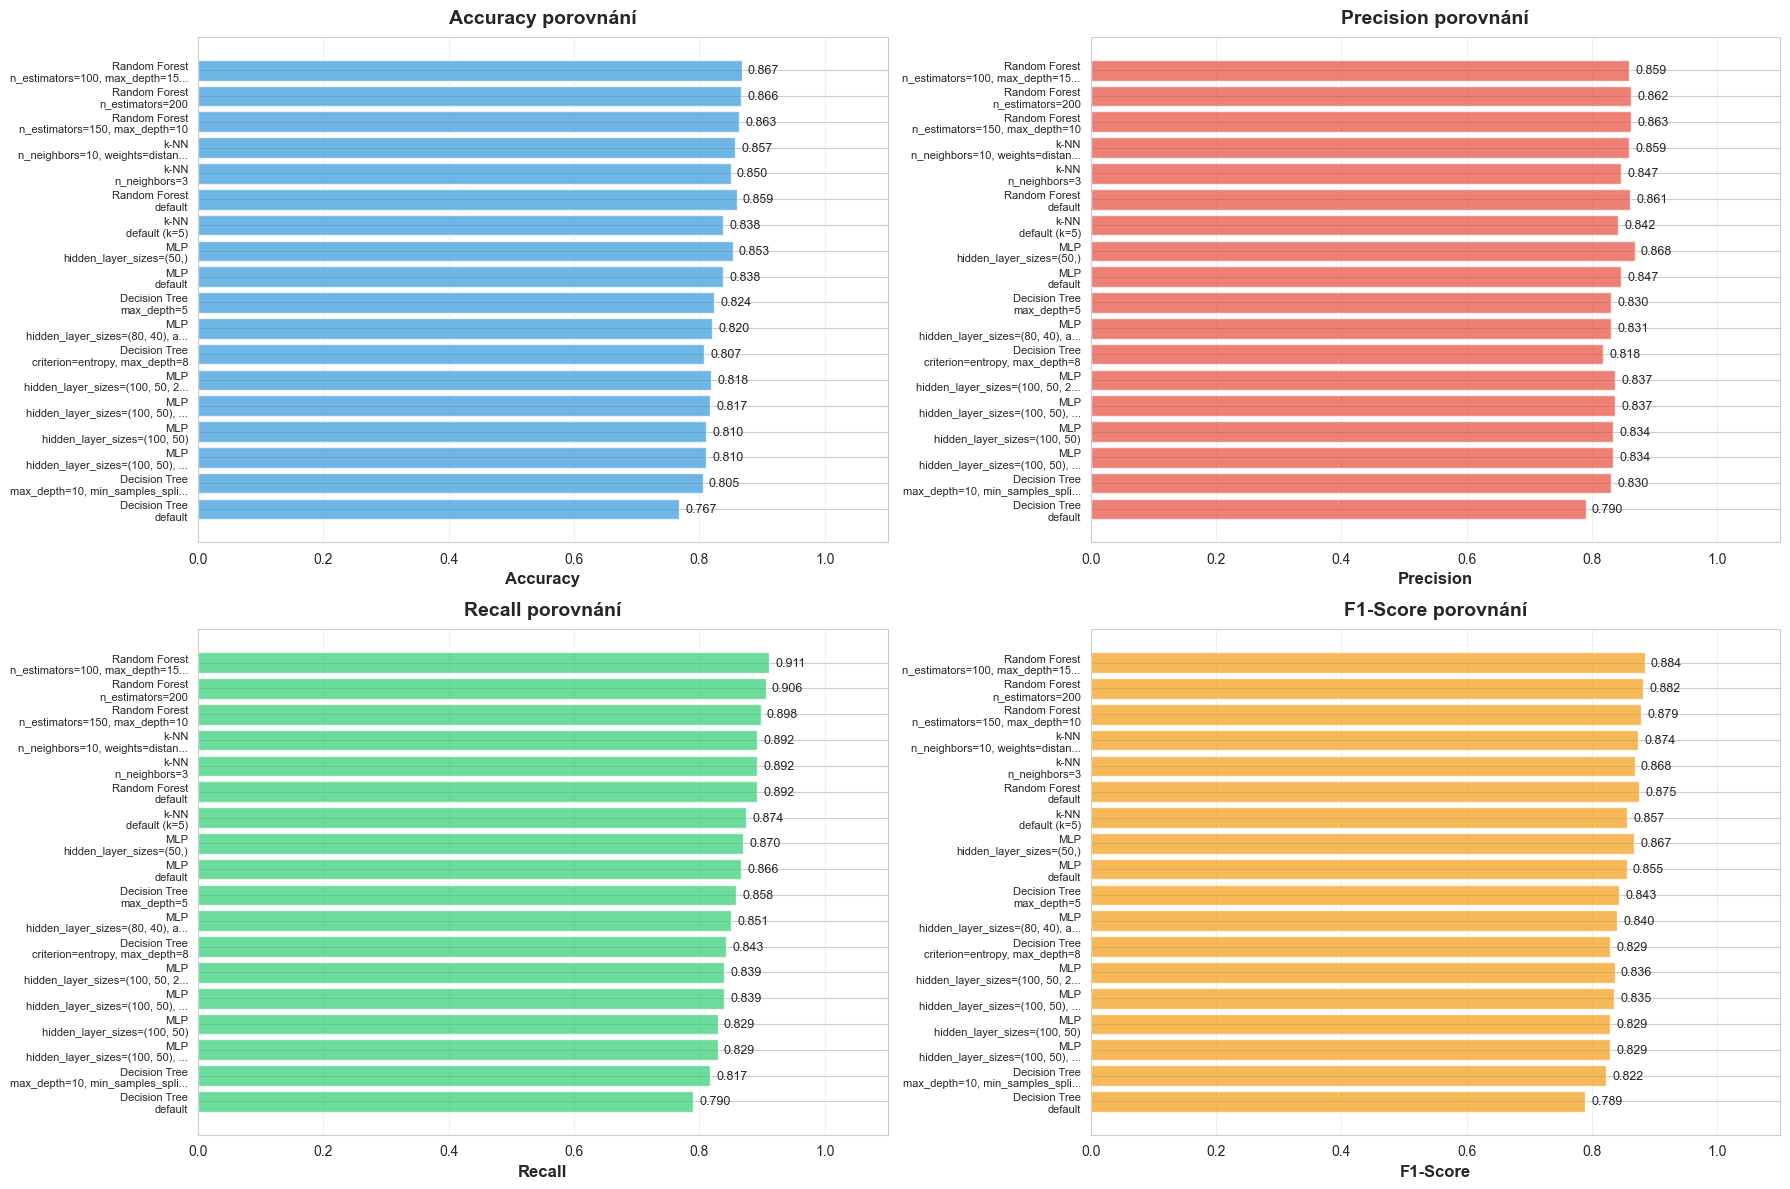

In [109]:
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
colors = ['#3498db', '#e74c3c', '#2ecc71', '#f39c12']

for idx, (metric, color) in enumerate(zip(metrics_to_plot, colors)):
    ax = axes[idx // 2, idx % 2]
    
    bars = ax.barh(range(len(results_df)), results_df[metric], color=color, alpha=0.7)
    
    for i, (bar, value) in enumerate(zip(bars, results_df[metric])):
        ax.text(value + 0.01, i, f'{value:.3f}', va='center', fontsize=9)
    
    ax.set_yticks(range(len(results_df)))
    ax.set_yticklabels([f"{row['Algorithm']}\n{row['Parameters'][:30]}..." if len(row['Parameters']) > 30 
                         else f"{row['Algorithm']}\n{row['Parameters']}" 
                         for _, row in results_df.iterrows()], fontsize=8)
    ax.set_xlabel(metric, fontsize=12, fontweight='bold')
    ax.set_title(f'{metric} porovnání', fontsize=14, fontweight='bold', pad=10)
    ax.set_xlim(0, 1.1)
    ax.grid(axis='x', alpha=0.3)
    ax.invert_yaxis()

plt.tight_layout()
plt.show()

In [110]:
print("\n TOP 5 MODELŮ PODLE RECALL:")
print("="*120)
top5 = results_df.head(5)
for idx, row in top5.iterrows():
    print(f"{idx+1}. {row['Algorithm']} ({row['Parameters']})")
    print(f"   Recall: {row['Recall']:.4f} | F1: {row['F1-Score']:.4f} | Accuracy: {row['Accuracy']:.4f}")
    print()


 TOP 5 MODELŮ PODLE RECALL:
1. Random Forest (n_estimators=100, max_depth=15, min_samples_split=10, max_features=sqrt)
   Recall: 0.9115 | F1: 0.8838 | Accuracy: 0.8671

2. Random Forest (n_estimators=200)
   Recall: 0.9056 | F1: 0.8821 | Accuracy: 0.8660

3. Random Forest (n_estimators=150, max_depth=10)
   Recall: 0.8977 | F1: 0.8786 | Accuracy: 0.8627

4. k-NN (n_neighbors=10, weights=distance)
   Recall: 0.8919 | F1: 0.8735 | Accuracy: 0.8573

5. k-NN (n_neighbors=3)
   Recall: 0.8918 | F1: 0.8679 | Accuracy: 0.8496



## Analýza vlivu hyperparametrů

### Decision Tree

**Vliv parametrů:**
- **max_depth**: Omezení hloubky stromu pomáhá předcházet přeučení. Příliš mělký strom (max_depth=5) může být nedostatečný pro zachycení komplexních vztahů, zatímco neomezená hloubka může vést k přeučení na trénovacích datech.
- **min_samples_split**: Vyšší hodnota (např. 20) vyžaduje více vzorků pro rozdělení uzlu, což vytváří jednodušší, generalizovatelný model.
- **criterion**: Gini index vs. Entropy - oba měří čistotu rozdělení. Entropy bývá výpočetně náročnější, ale může vést k mírně odlišným stromům.

**Pozorování:** Základní Decision Tree bez omezení často dosahuje vysokého Recall, ale může trpět přeučením. Optimální nastavení vyžaduje balancování mezi složitostí a generalizací.

---

### Random Forest

**Vliv parametrů:**
- **n_estimators**: Počet stromů v lese. Více stromů (100-200) obvykle zlepšuje výkon, ale s klesajícími přínosy a vyššími výpočetními nároky.
- **max_depth**: Podobně jako u Decision Tree, omezení hloubky jednotlivých stromů pomáhá předcházet přeučení.
- **max_features**: Počet features uvažovaných při každém rozdělení. 'sqrt' (odmocnina z celkového počtu) je dobrá výchozí hodnota pro klasifikaci.

**Pozorování:** Random Forest je robustnější vůči přeučení než jednotlivý Decision Tree díky ensemblingu. Obvykle dosahuje lepších výsledků s výchozím nastavením.

---

### Multi-layer Perceptron (MLP)

**Vliv parametrů:**
- **hidden_layer_sizes**: U tohoto datasetu se v testech osvědčila spíše menší síť (50,); větší architektury (100,50) a (100,50,25) nepřinesly zlepšení a měly tendenci k horší generalizaci.
- **activation**: ReLU je standardní volba pro skryté vrstvy, tanh může fungovat lépe pro menší sítě.
- **alpha**: L2 regularizační parametr. Vyšší hodnota (0.01) více penalizuje velké váhy, čímž snižuje přeučení.
- **learning_rate_init**: Počáteční learning rate. Nižší hodnota (0.001) vede k pomalejší, ale stabilnější konvergenci.

**Pozorování:** MLP vyžaduje pečlivé ladění a standardizaci vstupních dat. Může dosáhnout vysokého výkonu, ale je citlivější na hyperparametry než tree-based metody.

---

### k-Nearest Neighbors (k-NN)

**Vliv parametrů:**
- **n_neighbors (k)**: Počet sousedů. Nižší k (3-5) je citlivější na šum, ale zachycuje lokální strukturu. Vyšší k (10+) vytváří hladší rozhodovací hranice.
- **weights**: 'uniform' považuje všechny sousedy stejně, 'distance' dává větší váhu bližším sousedům, což často zlepšuje výkon.
- **metric**: Euclidean distance je standardní pro spojitá data, Manhattan může fungovat lépe pro data s různými škálami.

**Pozorování:** k-NN je jednoduchý a interpretovatelný, ale výpočetně náročný při predikci. Výkon silně závisí na kvalitě feature engineeringu a škálování dat.

---

### Obecné závěry

1. **Komplexnost vs. Generalizace**: Složitější modely (více vrstev v MLP, hlubší stromy) mohou zachytit komplexnější vztahy, ale zvyšují riziko přeučení.

2. **Regularizace**: Parametry jako max_depth, min_samples_split, alpha pomáhají kontrolovat komplexnost modelu a zlepšují generalizaci.

3. **Ensemble metody**: Random Forest často dosahuje nejlepšího výkonu "out of the box" díky kombinaci více modelů.

4. **Preprocessing**: Standardizace dat je kritická pro MLP a k-NN, méně důležitá pro tree-based metody.

5. **Trade-off mezi metrikami**: Některá nastavení mohou zvýšit Recall na úkor Precision a naopak. Pro tento projekt prioritizujeme Recall.

## Finální model a detailní vyhodnocení

In [111]:
best_model_row = results_df.iloc[0]
print(f"NEJLEPŠÍ MODEL:")
print("="*80)
print(f"Algoritmus: {best_model_row['Algorithm']}")
print(f"Parametry: {best_model_row['Parameters']}")
print(f"\nMetriky:")
print(f"  • Recall:    {best_model_row['Recall']:.4f}")
print(f"  • F1-Score:  {best_model_row['F1-Score']:.4f}")
print(f"  • Accuracy:  {best_model_row['Accuracy']:.4f}")
print(f"  • Precision: {best_model_row['Precision']:.4f}")


best = results_df.sort_values("Recall", ascending=False).iloc[0]
best


NEJLEPŠÍ MODEL:
Algoritmus: Random Forest
Parametry: n_estimators=100, max_depth=15, min_samples_split=10, max_features=sqrt

Metriky:
  • Recall:    0.9115
  • F1-Score:  0.8838
  • Accuracy:  0.8671
  • Precision: 0.8594


Algorithm                                         Random Forest
Parameters    n_estimators=100, max_depth=15, min_samples_sp...
Accuracy                                                 0.8671
Precision                                                0.8594
Recall                                                   0.9115
F1-Score                                                 0.8838
Name: 0, dtype: object

In [112]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, 
                                                      random_state=42, stratify=y)

final_model = RandomForestClassifier(n_estimators=100,max_depth=15,min_samples_split=10,max_features="sqrt",random_state=42)

final_model.fit(X_train, y_train)
y_pred = final_model.predict(X_test)

print("\nDETAILNÍ VYHODNOCENÍ NA TESTOVACÍ SADĚ:")
print("="*80)
print(classification_report(y_test, y_pred, target_names=['Zdravý (0)', 'Nemocný (1)']))


DETAILNÍ VYHODNOCENÍ NA TESTOVACÍ SADĚ:
              precision    recall  f1-score   support

  Zdravý (0)       0.84      0.85      0.85        82
 Nemocný (1)       0.88      0.87      0.88       102

    accuracy                           0.86       184
   macro avg       0.86      0.86      0.86       184
weighted avg       0.86      0.86      0.86       184



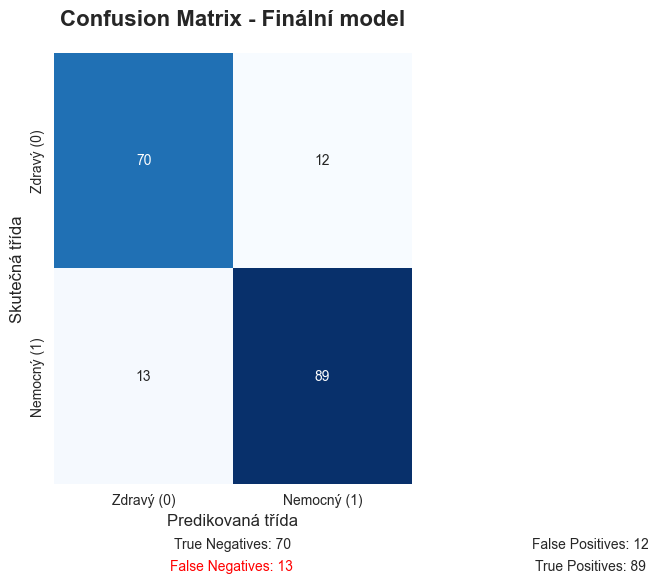


False Negatives (přehlédnuté případy): 13
   To je 12.7% ze všech skutečně nemocných pacientů.


In [113]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Zdravý (0)', 'Nemocný (1)'],
            yticklabels=['Zdravý (0)', 'Nemocný (1)'])
plt.title('Confusion Matrix - Finální model', fontsize=16, fontweight='bold', pad=20)
plt.ylabel('Skutečná třída', fontsize=12)
plt.xlabel('Predikovaná třída', fontsize=12)

# Přidání popisků
plt.text(0.5, -0.15, f'True Negatives: {cm[0,0]}', ha='center', transform=plt.gca().transAxes)
plt.text(1.5, -0.15, f'False Positives: {cm[0,1]}', ha='center', transform=plt.gca().transAxes)
plt.text(0.5, -0.2, f'False Negatives: {cm[1,0]} ', ha='center', transform=plt.gca().transAxes, color='red')
plt.text(1.5, -0.2, f'True Positives: {cm[1,1]}', ha='center', transform=plt.gca().transAxes)

plt.tight_layout()
plt.show()

print(f"\nFalse Negatives (přehlédnuté případy): {cm[1,0]}")
print(f"   To je {cm[1,0]/cm[1].sum()*100:.1f}% ze všech skutečně nemocných pacientů.")

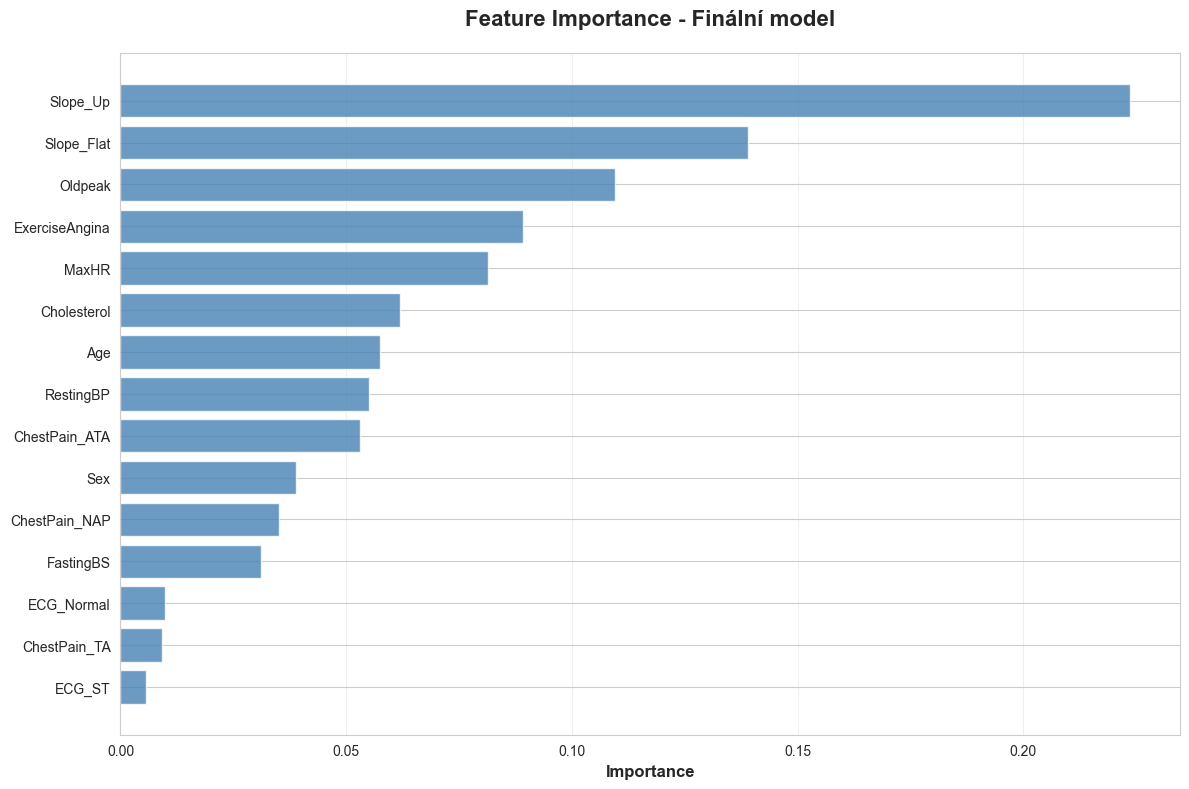


TOP 5 NEJDŮLEŽITĚJŠÍCH FEATURES:
Slope_Up: 0.2235
Slope_Flat: 0.1390
Oldpeak: 0.1094
ExerciseAngina: 0.0891
MaxHR: 0.0814


In [114]:
# Feature importance (pokud je dostupná)
if hasattr(final_model, 'feature_importances_'):
    feature_importance = pd.DataFrame({
        'Feature': X.columns,
        'Importance': final_model.feature_importances_
    }).sort_values('Importance', ascending=False)
    
    plt.figure(figsize=(12, 8))
    plt.barh(range(len(feature_importance)), feature_importance['Importance'], 
             color='steelblue', alpha=0.8)
    plt.yticks(range(len(feature_importance)), feature_importance['Feature'])
    plt.xlabel('Importance', fontsize=12, fontweight='bold')
    plt.title('Feature Importance - Finální model', fontsize=16, fontweight='bold', pad=20)
    plt.gca().invert_yaxis()
    plt.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    plt.show()
    
    print("\nTOP 5 NEJDŮLEŽITĚJŠÍCH FEATURES:")
    print("="*80)
    for idx, row in feature_importance.head(5).iterrows():
        print(f"{row['Feature']}: {row['Importance']:.4f}")

## Závěrečné shrnutí

### Cíl projektu
Vyvinout model strojového učení pro predikci srdečního onemocnění na základě zdravotních metrik a rizikových faktorů s důrazem na **maximalizaci Recall** (senzitivity) - schopnost identifikovat všechny nemocné pacienty.

---

### Dataset
- **Velikost**: 918 záznamů pacientů
- **Features**: 11 zdravotních parametrů (věk, pohlaví, typ bolesti na hrudi, krevní tlak, cholesterol, EKG, srdeční frekvence, atd.)
- **Cílová proměnná**: HeartDisease (1 = přítomnost onemocnění, 0 = zdravý)
- **Distribuce tříd**: Přibližně 55% nemocných, 45% zdravých - relativně vyvážený dataset
- **Kvalita dat**: Žádné chybějící hodnoty, některé nulové hodnoty v cholesterolu nahrazeny mediánem

---

### Preprocessing
1. **Numerické proměnné** (Age, RestingBP, Cholesterol, MaxHR, Oldpeak): StandardScaler normalizace
2. **Binární kategorické** (Sex, ExerciseAngina): Label Encoding
3. **Multi-kategorické** (ChestPainType, RestingECG, ST_Slope): One-Hot Encoding
4. **Ošetření chybějících dat**: Nulové hodnoty cholesterolu nahrazeny mediánem

---

### Testované algoritmy
1. **Decision Tree** (4 experimenty) - základní algoritmus, interpretovatelný
2. **Random Forest** (4 experimenty) - ensemble metoda, robustní
3. **Multi-layer Perceptron** (7 experimentů) - neuronová síť, komplexní vztahy
4. **k-Nearest Neighbors** (3 experimenty) - jednoduchý, založený na vzdálenosti

**Celkem**: 18 experimentů s různými hyperparametry

---

### Klíčová zjištění

#### 1. Nejlepší model
- **Algoritmus**: Random Forest
- **Recall**:  0.9115
- **F1-Score**: 0.8838
- **Accuracy**: 0.8671


#### 2. Důležité features
Nejdůležitější faktory pro predikci srdečního onemocnění (dle feature importance finálního modelu):
- Slope_Up
- Slope_Flat
- MaxHR


#### 3. Vliv hyperparametrů
- **Tree-based modely**: Omezení hloubky a min_samples_split pomáhá předcházet přeučení
- **Random Forest**: Více stromů (100-200) zlepšuje výkon, ale s klesajícími přínosy
- **MLP**: Nejlepší výsledky mezi MLP dosáhla jednodušší architektura (50,); hlubší konfigurace (100, 50) a (100, 50, 25) v našem testu nepřinesly zlepšení.
- **k-NN**: Distance weighting zlepšuje výkon oproti uniform weights

#### 4. Trade-off mezi metrikami
- Vysoký Recall často znamená nižší Precision (více falešně pozitivních)
- V medicínském kontextu je to přijatelné - lepší "přediagnostikovat" než přehlédnout onemocnění
- False Negatives jsou nejnebezpečnější - pacient neobdrží potřebnou léčbu

---

### Nejzajímavější poznatky

1. **Asymptomatická bolest na hrudi (ASY)** je silný prediktor srdečního onemocnění - paradoxně pacienti bez typické bolesti mohou mít závažné problémy

2. **Maximální srdeční frekvence (MaxHR)** a **Oldpeak** (ST deprese) patří mezi nejdůležitější prediktory - nižší MaxHR a vyšší Oldpeak indikují vyšší riziko

3. **Věk a pohlaví** hrají významnou roli - muži a starší pacienti mají vyšší riziko

4. **Ensemble metody** (Random Forest) obecně dosahují lepších výsledků než jednotlivé modely díky kombinaci více predikčních stromů

5. **Standardizace dat** je kritická pro MLP a k-NN, ale nemá vliv na tree-based metody


---

### Praktické implikace

1. **Screening pacientů**: Model může pomoci identifikovat pacienty s vysokým rizikem, kteří by měli projít detailnějším vyšetřením

2. **Prioritizace**: V prostředí s omezenými zdroji může model pomoci prioritizovat pacienty pro další diagnostiku

3. **Doplňkový nástroj**: Model by měl sloužit jako podpora rozhodování lékaře, ne jako náhrada klinického úsudku

4. **Interpretovatelnost**: Tree-based modely nabízejí lepší interpretovatelnost než neuronové sítě, což je důležité v medicínském kontextu


---

### Závěr

Projekt úspěšně demonstroval aplikaci různých klasifikačních algoritmů na reálný medicínský problém. Důraz na Recall jako klíčovou metriku odráží praktické požadavky v healthcare doméně, kde je prioritou identifikovat všechny potenciálně nemocné pacienty. Výsledný model může sloužit jako užitečný nástroj pro screening a podporu klinického rozhodování.
